In [311]:
import sys
from pathlib import Path
import numpy as np
import yaml
import jax
import gc
from tqdm.notebook import tqdm
from dataclasses import replace
from matplotlib.cm import ScalarMappable
from matplotlib.collections import LineCollection
import colormaps as cmaps

ROOT = Path("/home/kzeleznikar/IJS-F1/Koda")
CFG = ROOT / "EI_cutoff" / "config" / "config_ibz.yaml"

# Ensure the root folder is in Python's search path
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import EI.ei_unified as eu
from EI_baths.phase_map_plots import plot_maps, scan_maps
from EI_baths.fixed_baths import (
    plot_bz,
    plot_dispersion,
    plot_energy,
    plot_xi,
    solve_state,
    solve_teff,
)
from utils.cosmetics import apply_plt_style
from utils.logger import logger
from utils.plotting_utils import Plotter
import EI.ei_unified as eu
import EI.ei_jax_2 as ej
import EI.ei_phonon as pb
from EI.ei_anderson import solve_anderson

from utils.logger import logger, tqdm_bar
from utils.plotting_utils import Plotter, plot_cmap, format_ax, add_legend, plot_cmap, plot_phase_diag, color_map
from EI_baths.fixed_baths import k_path, take_path, color_line, solve_state, plot_dispersion

apply_plt_style()
pt = Plotter(show=True, close=False)

from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png", dpi=300)
from utils.cosmetics import SET1_LIST

FIG_PATH = "/home/kzeleznikar/IJS-F1/Notes/latex/figures/"

In [312]:
import numpy as np
import matplotlib.pyplot as plt
from EI_refactor.EI_ness import model as M, baths as B
from EI_refactor.EI_ness import gpu as S  # or gpu

md = M.Model(gap=4.0, ta=1.0, tb=-1.0, v=4.1) 
g = M.sgrid(240, 128)
e0 = M.solve_eq(md, g, 0.0, d=1.0)
tc = M.critical_temperature(md, g)
print(f"Delta_0 = {e0.d:.6f} = {e0.d * 0.1 * 11600:.6f} K, m_0 = {e0.m:.6f}, T_c = {tc * 0.1 * 11600:.6f} K")

Delta_0 = 0.083537 = 96.902372 K, m_0 = -0.995752, T_c = 56.637106 K


In [313]:
print(f"omega_D = {np.sqrt(4 * np.pi) * 0.026 * 0.1* 11600} K")

omega_D = 106.9144162866207 K


In [314]:
r1, r2, A = 0.8, 0.1, 1.0 # T1 / Tc (photons), T2 / Tc (phonons), photon amplitude scale
t1, t2 = r1 * tc, r2 * tc
bs = [B.Cavity(t1, w0=0.08, gam=0.0001, amp=A * 4 * B.ALPHA * 0.1),
      B.Chord(t2, cs=0.026, gam=0.001, amp=4.2e-6, tpa=1.0, tpb=-1.0)]
pk = B.pack(bs, md, g)
eq = M.solve_eq(md, g, t2, d=e0.d, m=e0.m) 

In [315]:
s = S.solve(md, g, pk, d=eq.d, m=eq.m)
print(f"Delta / Delta_0 = {s.d / e0.d:.6f}, m = {s.m:.6f}, err = {s.err:.1e}, ok = {s.ok}")

Delta / Delta_0 = 0.989385, m = -0.995800, err = 4.1e-11, ok = True


/tmp/ipykernel_30695/1254354844.py:6: RuntimeWarning: overflow encountered in exp
  ax.plot(ee, 1.0 / (1.0 + np.exp((ee * e0.d - mu) / t)), color=SET1_LIST[i], label=lab)


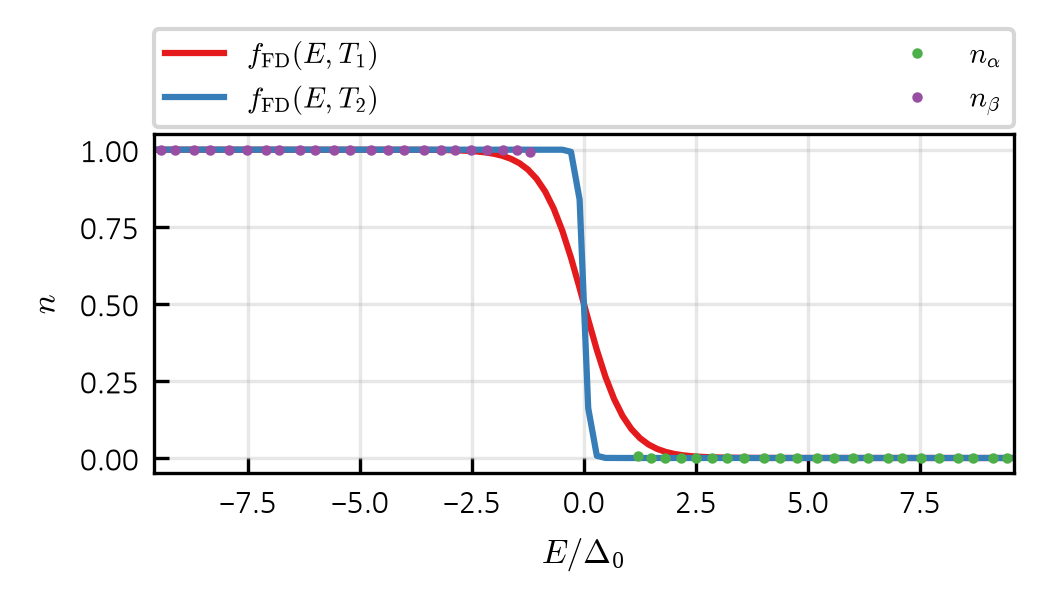

In [316]:
fig, ax = plt.subplots(figsize=(3.47412, 0.6 * 3.47412))
e = s.st.e / e0.d
ee = np.linspace(e.min(), e.max(), 1000)
for i, (t, lab) in enumerate(((t1, r"$f_{\rm FD}(E, T_1)$"), (t2, r"$f_{\rm FD}(E, T_2)$"))):
    mu = M.fermi(s.st, g.w, md.n, t)[1]
    ax.plot(ee, 1.0 / (1.0 + np.exp((ee * e0.d - mu) / t)), color=SET1_LIST[i], label=lab)
ax.plot(e[0], s.n[0], ".", ms=3, color=SET1_LIST[2], label=r"$n_{\alpha}$")
ax.plot(e[1], s.n[1], ".", ms=3, color=SET1_LIST[3], label=r"$n_{\beta}$")
ax.set_xlim(ee[0] / 10 ,  ee[-1] / 10)
ax.set_xlabel(r"$E/\Delta_0$")
ax.set_ylabel(r"$n$")
ax.grid(alpha=0.3)
ax.tick_params(which="both", direction="in")
ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand",
          borderaxespad=0, ncol=2, fontsize=7)
plt.tight_layout()
plt.show()

/tmp/ipykernel_30695/1495329704.py:20: RuntimeWarning: overflow encountered in exp
  ax[0].plot(x[ix], 1.0 / (1.0 + np.exp(z)), "-", lw=0.8, color=SET1_LIST[2 + j],


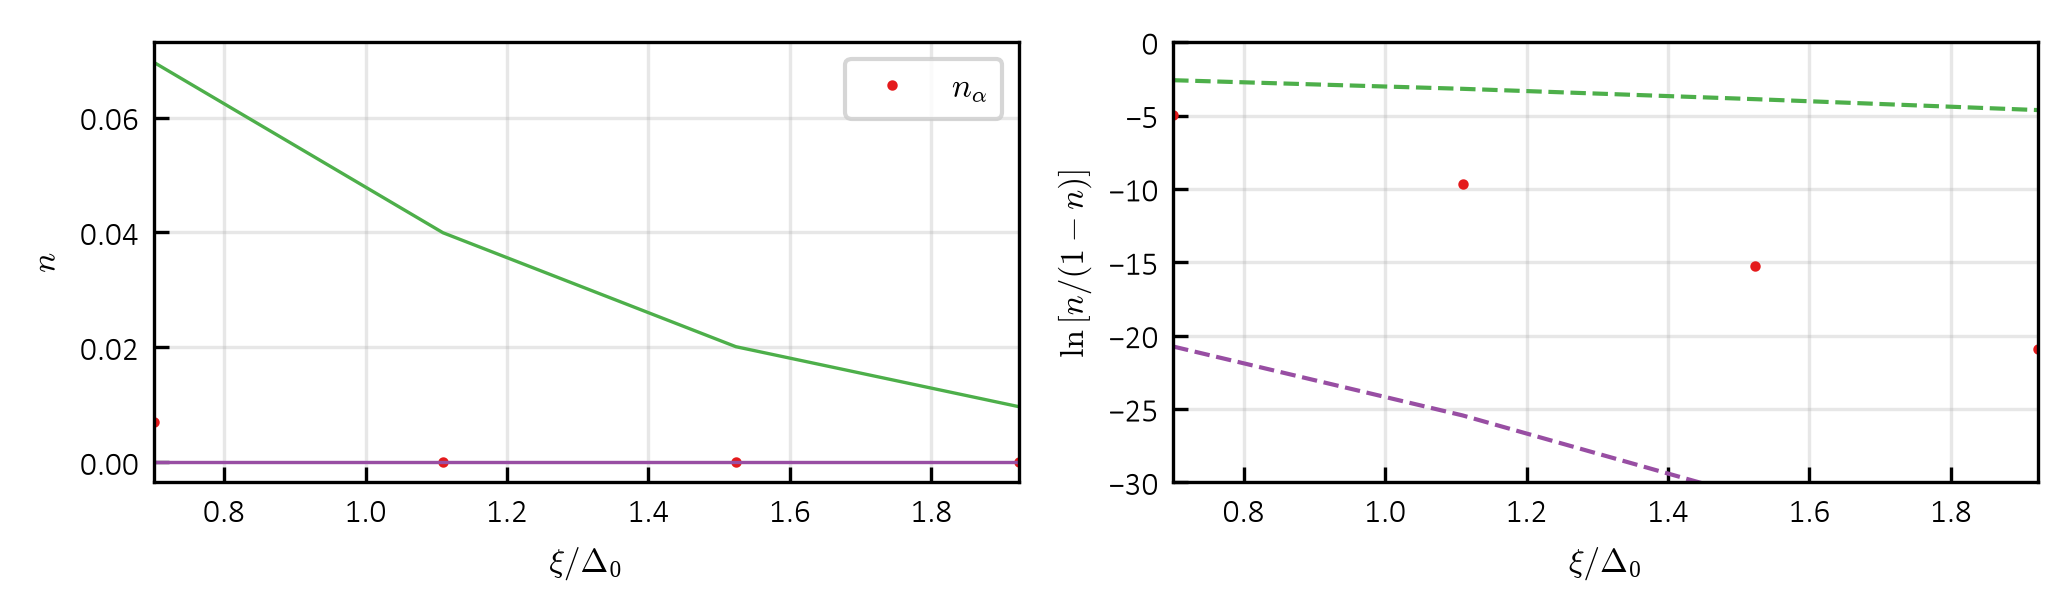

In [317]:
na, nb = 0.5 * (md.n + s.m), 0.5 * (md.n - s.m)
xi = 0.5 * (md.gap - 2.0 * (md.ta - md.tb) * g.s + md.h * (nb - na))  # (eps_a^H - eps_b^H) / 2
x = xi / e0.d

max_val = np.max(s.n[0])
threshold = 1e-8 * max_val
valid_mask = s.n[0] >= threshold

x_min = x[valid_mask].min()
x_max = x[valid_mask].max()

ix = np.argsort(x)
lab = r"{\alpha}"
fig, ax = plt.subplots(1, 2, figsize=(2 * 3.47412, 0.6 * 3.47412))
ax[0].plot(x, s.n[0], ".", ms=3, color=SET1_LIST[0], label=rf"$n_{lab}$")
ax[1].plot(x, -s.mu[0], ".", ms=3, color=SET1_LIST[0], label=rf"$n_{lab}$")
for j, (t, lab) in enumerate(((t1, "T_1"), (t2, "T_2"))):
    mu = M.fermi(s.st, g.w, md.n, t)[1]  # alpha solid, beta dashed
    z = (s.st.e[0][ix] - mu) / t
    ax[0].plot(x[ix], 1.0 / (1.0 + np.exp(z)), "-", lw=0.8, color=SET1_LIST[2 + j],
               label=rf"$f_{{\rm FD}}(E,{lab})$" if i == 0 else None)
    ax[1].plot(x[ix], -z, "--", lw=1, color=SET1_LIST[2 + j])
ax[0].set_ylabel(r"$n$")
ax[1].set_ylabel(r"$\ln\left[n/(1-n)\right]$")
for a in ax:
    a.set_xlim(x_min, x_max)
    a.set_xlabel(r"$\xi/\Delta_0$")
    a.grid(alpha=0.3)
    a.tick_params(which="both", direction="in")
ax[1].set_ylim(-30, 0)
ax[0].legend()
plt.tight_layout()
plt.show()

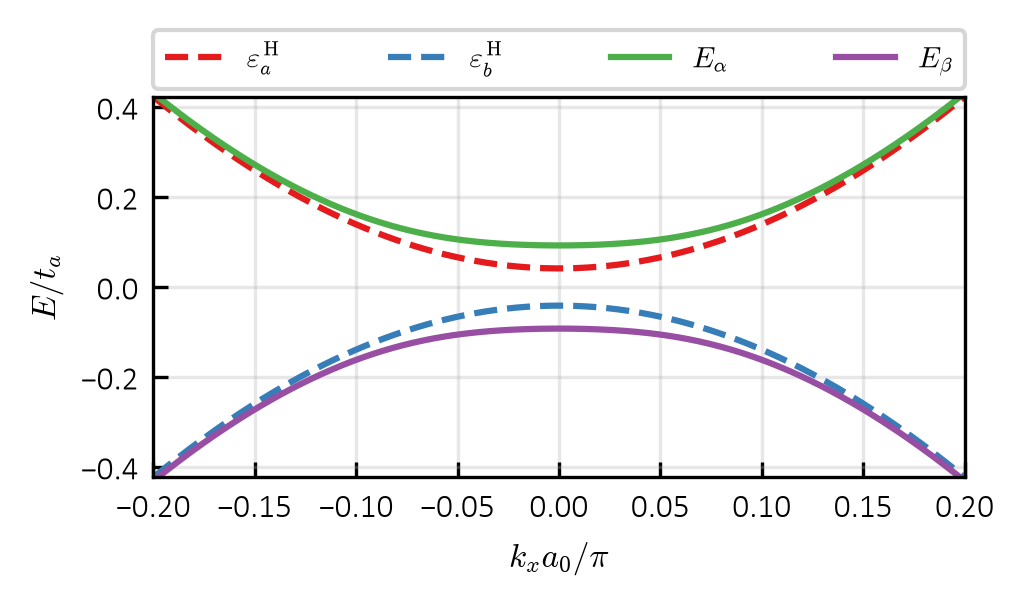

In [318]:
kx = np.linspace(-np.pi / 5, np.pi / 5, 401)
gk = g._replace(s=np.cos(kx) + 1.0)  # k_y = 0
stk = M.mf(md, gk, s.d, s.m)
eak = 0.5 * md.gap - 2.0 * md.ta * gk.s + md.h * (nb - 0.5)
ebk = -0.5 * md.gap - 2.0 * md.tb * gk.s + md.h * (na - 0.5)

fig, ax = plt.subplots(figsize=(3.47412, 0.6 * 3.47412))
ax.plot(kx / np.pi, eak, "--", color=SET1_LIST[0], label=r"$\varepsilon^{\rm H}_a$")
ax.plot(kx / np.pi, ebk, "--", color=SET1_LIST[1], label=r"$\varepsilon^{\rm H}_b$")
ax.plot(kx / np.pi, stk.e[0], color=SET1_LIST[2], label=r"$E_{\alpha}$")
ax.plot(kx / np.pi, stk.e[1], color=SET1_LIST[3], label=r"$E_{\beta}$")
ax.set_xlim(min(kx / np.pi), max(kx / np.pi))
ax.set_ylim(min(ebk), max(eak))
ax.set_xlabel(r"$k_x a_0 / \pi$")
ax.set_ylabel(r"$E / t_a$")
ax.grid(alpha=0.3)
ax.tick_params(which="both", direction="in")
ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand",
          borderaxespad=0, ncol=4, fontsize=7)
plt.tight_layout()
plt.show()

In [319]:
nw = g.wi.size
ww = np.tile(g.w[g.wi], 2)
bd = np.arange(2 * nw) >= nw                      # beta states
same = bd[:, None] == bd[None, :]                 # intraband pairs
rph = S.rates(md, g, s.st, B.pack([bs[1]], md, g))  # phonons only, R[dest, src]
rcv = S.rates(md, g, s.st, B.pack([bs[0]], md, g))  # cavity only

def out(r):
    """Total rate out of each source state, sum_dest R w_dest (no Pauli blocking), shape (2, nw)."""
    return (ww @ r).reshape(2, nw)

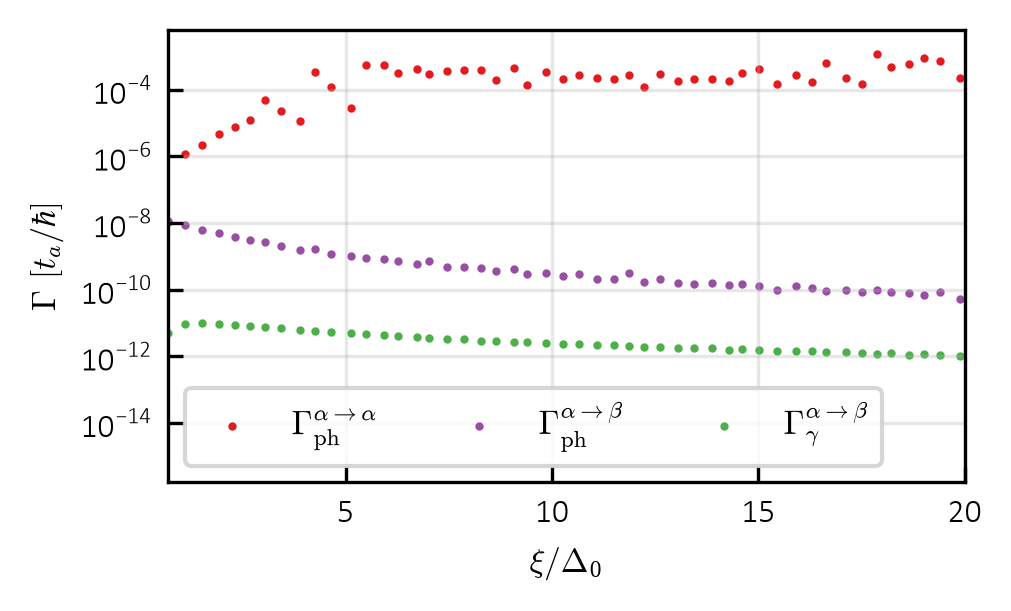

In [320]:
ga = {r"$\Gamma^{\alpha\to\alpha}_{\rm ph}$": out(np.where(same, rph, 0.0))[0],
      r"$\Gamma^{\alpha\to\beta}_{\rm ph}$": out(np.where(same, 0.0, rph))[0],
      r"$\Gamma_{\gamma}^{\alpha\to\beta}$": out(rcv)[0]}

fig, ax = plt.subplots(figsize=(3.47412, 0.6 * 3.47412))
for c, (lab, r) in zip((0, 3, 2), ga.items()):  # red, purple, green, blue
    ax.scatter(x, r, s=1, color=SET1_LIST[c], label=lab)

ax.set_yscale("log")
ax.set_xlim(x.min(), 20)
ax.set_xlabel(r"$\xi/\Delta_0$")
ax.set_ylabel(r"$\Gamma\ [t_a/\hbar]$")
ax.grid(alpha=0.3)
ax.tick_params(which="both", direction="in")
ax.legend(ncol=3)
plt.tight_layout()
plt.show()

In [321]:
print(out(rcv)[0].mean()/out(np.where(same, rph, 0.0))[0].mean())

2.212108867086242e-09


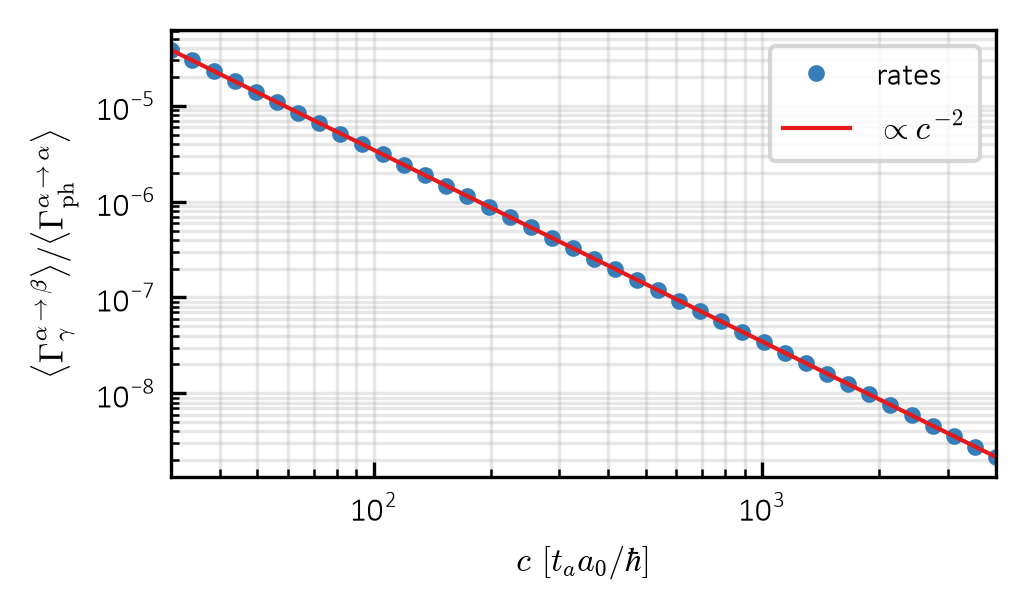

In [322]:
cs = np.geomspace(30, 4000, 40)                    # photon speed c
ph = out(np.where(same, rph, 0.0))[0].mean()       # phonon alpha -> alpha, independent of c
rr = np.array([out(S.rates(md, g, s.st, B.pack([B.Cavity(t1, w0=0.1, gam=0.01, c=c)], md, g)))[0].mean()
               for c in cs]) / ph

fig, ax = plt.subplots(figsize=(3.47412, 0.6 * 3.47412))
ax.loglog(cs, rr, ".", color=SET1_LIST[1], label="rates")
ax.loglog(cs, rr[-1] * (cs[-1] / cs) ** 2, color=SET1_LIST[0], lw=1, label=r"$\propto c^{-2}$")
ax.set_xlim(cs[0], cs[-1])
ax.set_xlabel(r"$c\ [t_a a_0/\hbar]$")
ax.set_ylabel(r"$\langle\Gamma^{\alpha\to\beta}_{\gamma}\rangle/\langle\Gamma^{\alpha\to\alpha}_{\rm ph}\rangle$")
ax.grid(alpha=0.3, which="both")
ax.tick_params(which="both", direction="in")
ax.legend()
plt.tight_layout()
plt.show()

In [323]:
from matplotlib.colors import Normalize

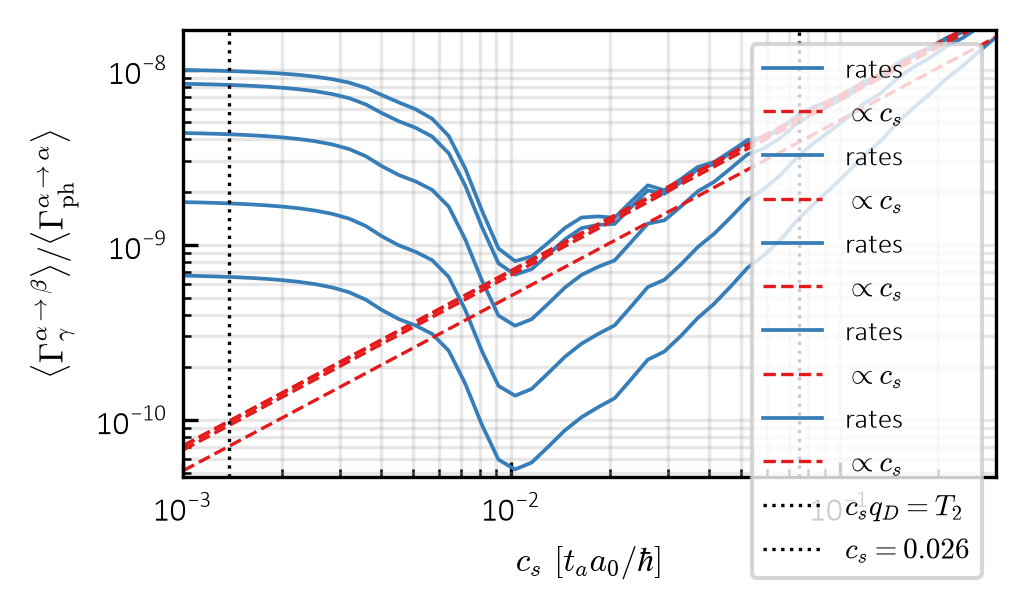

In [325]:
vs = np.geomspace(0.001, 0.3, 50)  # phonon speed c_s
gm = out(S.rates(md, g, s.st, B.pack([B.Cavity(t1, w0=0.1, gam=0.01)], md, g)))[0].mean()  # independent of c_s
ts = np.geomspace(0.1, 5., 5)

fig, ax = plt.subplots(figsize=(3.47412, 0.6 * 3.47412))

for tref in ts:
    pr = []
    for v in vs:
        r = S.rates(md, g, s.st, B.pack([B.Chord(tref *tc, cs=v, gam=0.002, amp=4.2e-6, tpa=1.0, tpb=-1.0, nq=1024)], md, g))
        pr.append(out(np.where(same, r, 0.0))[0].mean())
    rv = gm / np.array(pr)

    ax.loglog(vs, rv, "-", color=SET1_LIST[1], label="rates", lw=0.9)
    ax.loglog(vs, rv[-1] * (vs / vs[-1]), "--", color=SET1_LIST[0], lw=0.8, label=r"$\propto c_s$")
ax.set_ylim( rv.min()*0.9, rv.max()*1.1)
ax.axvline(t2 / B.QD, color="k", ls=":", lw=0.8, label=r"$c_s q_D=T_2$")
ax.axvline(64/B.QD * 1/240, color="k", ls=":", lw=0.8, label=r"$c_s=0.026$")
ax.set_xlim(vs[0], vs[-1])
ax.set_xlabel(r"$c_s\ [t_a a_0/\hbar]$")
ax.set_ylabel(r"$\langle\Gamma^{\alpha\to\beta}_{\gamma}\rangle/\langle\Gamma^{\alpha\to\alpha}_{\rm ph}\rangle$")
ax.grid(alpha=0.3, which="both")
ax.tick_params(which="both", direction="in")
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

In [307]:
print(0.1/tc)

2.0777265659213078


0it [00:00, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

... (7 outputs left out)

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

failed points: 0


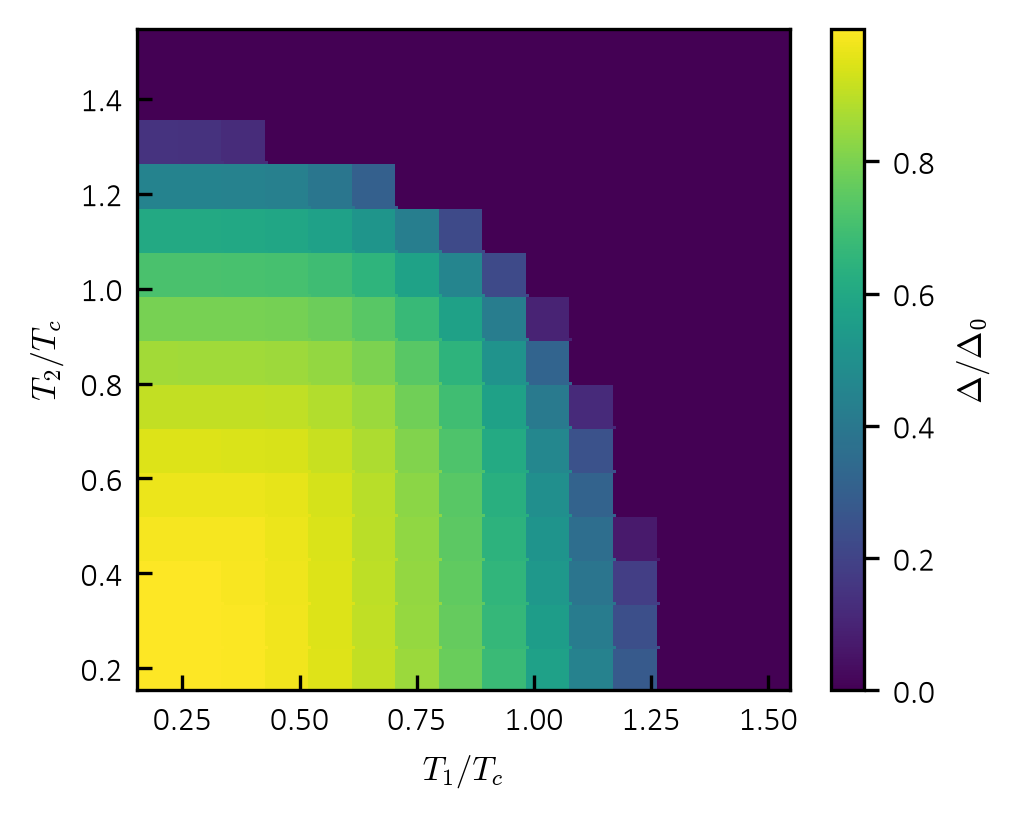

In [258]:
r1 = np.linspace(0.2, 1.5, 15)  # T1 / Tc (photons)
r2 = np.linspace(0.2, 1.5, 15)  # T2 / Tc (phonons)
A = 1e6                     # photon amplitude scale
dm, mm, ok = (np.full((r2.size, r1.size), np.nan) for _ in range(3))

eq = M.solve_eq(md, g, r2[0] * tc, d=e0.d, m=e0.m)
d, m, mu = eq.d, eq.m, None
for i, t2 in tqdm(enumerate(r2 * tc)):
    js = range(r1.size) if i % 2 == 0 else range(r1.size - 1, -1, -1)  # serpentine
    for j in tqdm(js, leave=False):
        bs = [B.Cavity(r1[j] * tc, w0=0.1, gam=0.01, amp=A * 4 * B.ALPHA * 0.1),
              B.Chord(t2, cs=0.13, gam=0.1, amp=4.2e-5, tpa=1.0, tpb=-1.0)]
        s = S.solve(md, g, B.pack(bs, md, g), d=max(d, 1e-3 * e0.d), m=m, mu=mu)
        d, m, mu = s.d, s.m, s.mu  # continuation
        dm[i, j], mm[i, j], ok[i, j] = s.d / e0.d, s.m, s.ok
print("failed points:", int((ok == 0).sum()))

fig, ax = plt.subplots(figsize=(3.47412, 0.8 * 3.47412))
im = ax.pcolormesh(r1, r2, dm, shading="nearest", cmap="viridis", rasterized=True)
im.set_edgecolor("face")
cbar = plt.colorbar(im, ax=ax)
cbar.set_label(r"$\Delta/\Delta_0$", rotation=90, labelpad=5)
ax.set_xlabel(r"$T_1/T_c$")
ax.set_ylabel(r"$T_2/T_c$")
ax.tick_params(which="both", direction="in")
plt.tight_layout()
plt.show()